# Logistic regression: disrupted airport-days

This notebook fits a logistic regression that estimates the probability that an airport-day is disrupted. The data (`data/processed/airport_day.parquet`) has one row per airport and day for 12 German airports, 2014–2025. The target `disrupted_day` is 1 if at least 2% of arrivals had more than 15 minutes of ATFM delay; this threshold is a project definition, not an official one. Predictors are the 37 columns approved in the feature contract (calendar, history from earlier days, same-day weather). The data is split by calendar year:

| Period | Years | Use |
|---|---|---|
| train | 2014–2021 | fit the model |
| select | 2022 | compare settings, fit the calibration mappings |
| calibrate | 2023 | choose the calibration method and alert threshold |
| test | 2024–2025 | final evaluation, scored once |

Same-day observed weather is used as if it were a perfect forecast, so this is a retrospective study and the scores are an upper bound for a real day-ahead system. The history columns are assumed to be available at the start of the day; actual EUROCONTROL publication times were not checked. The 2024–2025 period was looked at in earlier project work, so it is a previously inspected test period rather than an untouched one, but it is not used for any decision here.

## 1. Setup

In [1]:
# 1 setup
# Libraries, a fixed random seed and the paths to the data file and the feature
# contract. Versions are printed so the results can be reproduced.
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

RANDOM_SEED = 42

# The notebooks live in notebooks/, so the repository root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airport_day.parquet"
CONTRACT_PATH = PROJECT_ROOT / "data" / "processed" / "feature_contract.json"

print("Python:      ", platform.python_version())
print("pandas:      ", pd.__version__)
print("numpy:       ", np.__version__)
print("scikit-learn:", sklearn.__version__)
print()
print("Random seed:", RANDOM_SEED)
print("Data file found:    ", DATA_PATH.exists(), "->", DATA_PATH.relative_to(PROJECT_ROOT))
print("Contract file found:", CONTRACT_PATH.exists(), "->", CONTRACT_PATH.relative_to(PROJECT_ROOT))

Python:       3.13.14
pandas:       3.0.3
numpy:        2.4.6
scikit-learn: 1.9.0

Random seed: 42
Data file found:     True -> data/processed/airport_day.parquet
Contract file found: True -> data/processed/feature_contract.json


## 2. Data checks

In [2]:
# 2.1 load the dataset
# Parquet keeps the column types (dates, booleans, integers with missing values)
# that a CSV would lose.
airport_days = pd.read_parquet(DATA_PATH)

print("Rows:   ", airport_days.shape[0])
print("Columns:", airport_days.shape[1])

Rows:    52596
Columns: 79


The next cell shows three Frankfurt rows with a subset of columns. `arrivals` is the number of arriving flights, `atfm_delay_min` the total ATFM delay and `arrivals_atfm_delayed_15` the number of arrivals delayed by more than 15 minutes. Dates are UTC.

In [3]:
# 2.2 a few rows for Frankfurt (EDDF), showing only some of the columns
# Quick look at what one airport-day row contains.
example_columns = [
    "airport_icao", "airport_name", "date", "arrivals", "atfm_delay_min",
    "arrivals_atfm_delayed_15", "temp_mean_c", "gust_max_ms",
    "disrupted_day", "atfm_delay_per_arrival",
]
frankfurt_rows = airport_days[airport_days["airport_icao"] == "EDDF"]
frankfurt_rows[example_columns].head(3)

,airport_icao,airport_name,date,arrivals,atfm_delay_min,arrivals_atfm_delayed_15,temp_mean_c,gust_max_ms,disrupted_day,atfm_delay_per_arrival
1,EDDF,Frankfurt,2014-01-01 00:00:00+00:00,362.0,0.0,0.0,4.575000,8.0,0,0.0
13,EDDF,Frankfurt,2014-01-02 00:00:00+00:00,560.0,1709.0,50.0,7.429167,15.0,1,3.051786
25,EDDF,Frankfurt,2014-01-03 00:00:00+00:00,564.0,1730.0,50.0,7.704167,NaN,1,3.067376


On 2 January 2014, 50 of 560 Frankfurt arrivals (8.9%) were delayed by more than 15 minutes, so the day is disrupted. The `NaN` gust value on 3 January is a real gap in the weather record.

In [4]:
# 2.3 which airports and dates are covered?
# Rows, first and last date per airport. With one row per calendar day,
# rows should equal the number of calendar days.
coverage = airport_days.groupby(["airport_icao", "airport_name"]).agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
)
# +1 because both the first and the last date are included
calendar_days = (airport_days["date"].max() - airport_days["date"].min()).days + 1

print("Number of airports:", coverage.shape[0])
print("Calendar days from the first to the last date:", calendar_days)
coverage

Number of airports: 12
Calendar days from the first to the last date: 4383


,,rows,first_date,last_date
airport_icao,airport_name,,,
EDDC,Dresden,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDF,Frankfurt,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDG,Muenster-Osnabrueck,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDH,Hamburg,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDK,Cologne-Bonn,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDL,Duesseldorf,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDM,Munich,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDN,Nuremberg,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDP,Leipzig-Halle,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00


All 12 airports have 4,383 rows, one for every day from 1 January 2014 to 31 December 2025 (12 × 4,383 = 52,596).

In [5]:
# 2.4 is any airport-date pair listed more than once?
# Each airport should have at most one row per date; duplicates would count a day twice.
# duplicated() marks every repeat after the first, so the sum counts the extra copies.
duplicate_count = airport_days.duplicated(subset=["airport_icao", "date"]).sum()
print("Duplicate airport-date rows:", duplicate_count)

Duplicate airport-date rows: 0


The feature contract, written when the dataset was built, lists the approved predictors (`predictor_allowlist`) and the same-day outcome columns that must not be used as inputs (`forbidden_same_day_outcomes`).

In [6]:
# 2.5 read the feature contract
# The contract lists the columns allowed as predictors and the same-day outcome
# columns that must never be used, because they are not known in advance.
import json

with open(CONTRACT_PATH) as contract_file:
    feature_contract = json.load(contract_file)

predictor_columns = feature_contract["predictor_allowlist"]
# Columns measured on the same day as the target (they would leak the answer)
forbidden_columns = feature_contract["forbidden_same_day_outcomes"]

print("Approved predictors:", len(predictor_columns))
# len(set(...)) shows whether the list contains repeated names
print("Entries in the forbidden list:", len(forbidden_columns), "| unique:", len(set(forbidden_columns)))
print("Contract note:", feature_contract["note"])

Approved predictors: 37
Entries in the forbidden list: 28 | unique: 27
Contract note: Target definition is EUROCONTROL ATFM airport arrival delay (network regulations), not gate/schedule punctuality.


37 approved predictors. The forbidden list has 28 entries but 27 unique names because `atfm_delay_min` appears twice; this does not matter for the overlap check.

In [7]:
# 2.6 data type and missing values for every approved predictor
# Needed to decide how missing values are handled in preprocessing (section 7).
predictor_overview = pd.DataFrame({
    "dtype": airport_days[predictor_columns].dtypes.astype(str),
    "missing_rows": airport_days[predictor_columns].isna().sum(),
})
predictor_overview["missing_percent"] = (100 * predictor_overview["missing_rows"] / len(airport_days)).round(2)
predictor_overview

,dtype,missing_rows,missing_percent
airport_icao,string,0,0.00
weekday,Int8,0,0.00
month,Int8,0,0.00
doy_sin,float64,0,0.00
doy_cos,float64,0,0.00
is_weekend,bool,0,0.00
is_public_holiday,bool,0,0.00
temp_mean_c,float64,185,0.35
temp_min_c,float64,185,0.35
temp_max_c,float64,185,0.35


- Airport and calendar columns are complete.
- Weather columns are missing on 0.35–1.57% of rows; visibility and the weather-code columns (fog, thunder, snow, freezing) have the most gaps.
- History columns are missing on less than 0.6% of rows, mostly at the start of the series and after gaps.
- Mixed data types (`string`, `Int8`, `bool`, `boolean`, `float64`) are converted to floats in cell 5.3, except the airport code.

In [8]:
# 2.7 does the dataset's own 'split' column agree with the planned years?
# crosstab counts rows per year and split label; each year should fall in exactly one split.
pd.crosstab(airport_days["year"], airport_days["split"])

split,calibrate,model_select,test,train
year,,,,
2014,0,0,0,4380
2015,0,0,0,4380
2016,0,0,0,4392
2017,0,0,0,4380
2018,0,0,0,4380
2019,0,0,0,4380
2020,0,0,0,4392
2021,0,0,0,4380
2022,0,4380,0,0


The dataset's `split` column matches the planned years. 2016, 2020 and 2024 have 4,392 rows because they are leap years.

## 3. Target and class balance

Missing labels are counted in all periods. Everything else in this section uses the training years only, so that exploration does not influence choices on later periods.

In [9]:
# 3.1 rows where the target is missing, and why (counts only)
# The target cannot be computed on some days. They are counted by reason and
# period here and dropped in section 5.
target_missing = airport_days["disrupted_day"].isna()
print("Rows with missing disrupted_day:", target_missing.sum())

missing_rows = airport_days[target_missing].copy()
missing_rows["reason"] = "other"
# Applied in order, so a row that matches both rules keeps the second reason
missing_rows.loc[~missing_rows["eurocontrol_row_present"], "reason"] = "no EUROCONTROL record for that day"
missing_rows.loc[missing_rows["arrivals"] == 0, "reason"] = "zero arrivals (share cannot be calculated)"
pd.crosstab(missing_rows["reason"], missing_rows["split"])

Rows with missing disrupted_day: 47


split,model_select,test,train
reason,,,
no EUROCONTROL record for that day,8,0,30
zero arrivals (share cannot be calculated),1,1,7


47 rows have no label: 38 have no EUROCONTROL record and 9 have zero arrivals, so the share is undefined. 37 are in training, 9 in 2022 and 1 in the test years. These rows are excluded rather than treated as not disrupted, since a missing record is not evidence of a normal day.

In [10]:
# 3.2 from here on, explore the training years only (2014-2021)
# Exploring only training years keeps 2022-2025 from influencing modelling choices.
# The check below confirms the stored label follows the 2% rule.
training_days = airport_days[(airport_days["year"] <= 2021) & ~target_missing].copy()
print("Training rows with a known target:", len(training_days))

# Re-calculate the 2% rule from the raw counts and compare it with the stored label
recalculated_share = training_days["arrivals_atfm_delayed_15"] / training_days["arrivals"]
recalculated_label = (recalculated_share >= 0.02).astype(int)
stored_label = training_days["disrupted_day"].astype(int)
print("Rows where our re-calculation disagrees with disrupted_day:", (recalculated_label != stored_label).sum())

Training rows with a known target: 35027
Rows where our re-calculation disagrees with disrupted_day: 0


Recomputing the 2% rule reproduces `disrupted_day` on all 35,027 labelled training rows.

In [11]:
# 3.3 class balance in the training data
# Disrupted days are a small minority, which matters for the choice of metrics.
class_counts = training_days["disrupted_day"].value_counts().sort_index()
class_percent = (100 * class_counts / class_counts.sum()).round(2)
pd.DataFrame({"days": class_counts, "percent": class_percent})

,days,percent
disrupted_day,,
0,32976,94.14
1,2051,5.86


2,051 of 35,027 training days (5.86%) are disrupted.

In [12]:
# 3.4 the accuracy of a rule that never predicts a disruption
# Because the classes are imbalanced this trivial rule already scores high accuracy,
# so accuracy is not used to judge the model.
always_normal_accuracy = (training_days["disrupted_day"] == 0).mean()
print(f"Accuracy of always predicting 'not disrupted': {always_normal_accuracy:.1%}")

Accuracy of always predicting 'not disrupted': 94.1%


A rule that never predicts disruption is 94.1% accurate, so accuracy is not used. Evaluation is based on average precision, precision and recall.

In [13]:
# 3.5 disruption rate by airport (training years)
# Shows how much the base rate differs between airports.
training_by_airport = training_days.groupby(["airport_icao", "airport_name"]).agg(
    days=("disrupted_day", "size"),
    disrupted_days=("disrupted_day", "sum"),
)
training_by_airport["rate_percent"] = (100 * training_by_airport["disrupted_days"] / training_by_airport["days"]).round(2)
training_by_airport.sort_values("rate_percent", ascending=False)

,,days,disrupted_days,rate_percent
airport_icao,airport_name,,,
EDDF,Frankfurt,2922,506,17.32
EDDL,Duesseldorf,2922,457,15.64
EDDM,Munich,2922,308,10.54
EDDH,Hamburg,2922,267,9.14
EDDK,Cologne-Bonn,2922,210,7.19
EDDP,Leipzig-Halle,2922,104,3.56
EDDW,Bremen,2919,92,3.15
EDDS,Stuttgart,2906,90,3.1
EDDV,Hannover,2922,10,0.34


Disruption rates differ strongly between airports: Frankfurt 17.3% and Düsseldorf 15.6%, while Münster-Osnabrück (EDDG) had 1 disrupted day in eight years, Dresden (EDDC) 2, Nuremberg (EDDN) 4 and Hannover (EDDV) 10. At these four airports there is very little to learn from.

In [14]:
# 3.6 disruption rate by year (training years)
# Shows how much the base rate changes from year to year.
training_by_year = training_days.groupby("year").agg(
    days=("disrupted_day", "size"),
    disrupted_days=("disrupted_day", "sum"),
)
training_by_year["rate_percent"] = (100 * training_by_year["disrupted_days"] / training_by_year["days"]).round(2)
training_by_year

,days,disrupted_days,rate_percent
year,,,
2014,4380,251,5.73
2015,4380,230,5.25
2016,4392,271,6.17
2017,4380,340,7.76
2018,4380,408,9.32
2019,4380,381,8.7
2020,4358,37,0.85
2021,4377,133,3.04


The rate rose from 5.7% (2014) to 9.3% (2018), then fell to 0.85% in 2020 and 3.0% in 2021 because of COVID. These two years are a quarter of the training data. The model has no COVID input (`covid_traffic_period` is not approved) and can only pick up the lower traffic through the arrival-history columns. Training without 2020–2021 would be a reasonable pre-specified experiment, but the planned full training period is kept here.

## 4. Predictors

Several columns are same-day outcomes in another form, for example `share_arrivals_delayed_15` (the quantity the target is built from) and `atfm_delay_min`. They are only known after the day is over, so using them would be leakage. History columns such as `delay_per_arrival_lag1` (yesterday) and `delay_per_arrival_mean_28d` (the 28 days before) are allowed; `atfm_delay_per_arrival` (today) is not.

In [15]:
# 4.1 group the approved predictors by when their information is available
# The contract records an availability assumption for each predictor (when its
# value would be known). Grouping by it makes those assumptions easy to check.
predictor_info = pd.DataFrame(feature_contract["predictors"])
predictor_info = predictor_info[predictor_info["name"].isin(predictor_columns)]
print("Approved predictors described in the contract:", len(predictor_info))
print()

for availability, group in predictor_info.groupby("availability_assumption"):
    print(f"{availability}  ({len(group)} columns)")
    print("   ", ", ".join(group["name"]))
    print()

Approved predictors described in the contract: 37

Computed from days strictly before the row's day (known at the start of the day)  (10 columns)
    arrivals_lag1, arrivals_lag7, arrivals_mean_7d, delay_per_arrival_lag1, share_delayed15_lag1, disrupted_lag1, delay_per_arrival_mean_7d, delay_per_arrival_mean_28d, disrupted_rate_28d, weather_delay_per_arrival_mean_28d

Known in advance  (7 columns)
    airport_icao, weekday, month, doy_sin, doy_cos, is_weekend, is_public_holiday

Same-day OBSERVED weather standing in for a day-ahead forecast (perfect-forecast assumption; scores are an upper bound)  (20 columns)
    temp_mean_c, temp_min_c, temp_max_c, frost_day, rh_mean_pct, wind_mean_ms, wind_max_ms, gust_max_ms, gust_hours_ge15, precip_sum_mm, precip_max_1h_mm, precip_hours, cold_precip_hours, vis_min_m, low_vis_hours_lt1000, vis_hours_lt5000, fog_hours, thunder_hours, snow_hours, freezing_hours



7 predictors are known in advance (airport, calendar), 10 are history computed from earlier days, and 20 are same-day observed weather. The perfect-forecast assumption applies to the weather columns, and the contract notes that scores are therefore an upper bound.

In [16]:
# 4.2 make sure no forbidden column or the target slipped into the predictor list
# Leakage check. The second part lists every column that is left out of the model.
overlap = set(predictor_columns) & set(forbidden_columns)
print("Predictors that are also forbidden outcomes:", sorted(overlap))
print("Is disrupted_day in the predictor list?", "disrupted_day" in predictor_columns)

unused_columns = []
for column in airport_days.columns:
    if column not in predictor_columns:
        unused_columns.append(column)
print()
print(len(unused_columns), "columns are NOT used as predictors:")
print(", ".join(unused_columns))

Predictors that are also forbidden outcomes: []
Is disrupted_day in the predictor list? False

42 columns are NOT used as predictors:
date, airport_name, dwd_station, arrivals, atfm_delay_min, arrivals_atfm_delayed, arrivals_atfm_delayed_15, atfm_version, delay_accident_min, delay_atc_capacity_min, delay_deicing_min, delay_equipment_non_atc_min, delay_aerodrome_capacity_min, delay_atc_industrial_min, delay_airspace_mgmt_min, delay_industrial_non_atc_min, delay_other_min, delay_special_event_min, delay_atc_routeing_min, delay_atc_staffing_min, delay_equipment_atc_min, delay_environment_min, delay_weather_min, delay_not_specified_min, delay_blank_in_source, eurocontrol_row_present, temp_valid_hours, wind_valid_hours, gust_valid_hours, precip_valid_hours, vis_valid_hours, ww_reported_hours, atfm_delay_per_arrival, share_arrivals_delayed_15, weather_delay_per_arrival, disrupted_day, severe_disrupted_day, any_atfm_delay_day, weather_atfm_day, year, covid_traffic_period, split


No approved predictor is on the forbidden list and the target is not included. The 42 unused columns are identifiers (`date`, `airport_name`, `dwd_station`, `atfm_version`, `split`, `year`), same-day outcomes (today's `arrivals`, total and cause-specific delay, shares, labels), data-quality fields (`*_valid_hours`, `eurocontrol_row_present`, `delay_blank_in_source`, `ww_reported_hours`) and the COVID flag. Today's `arrivals` is excluded because it is only known after the day.

In [17]:
# 4.3 a lag column is yesterday's value moved forward by one day (Frankfurt, a week in July 2019)
# Shows that lag columns hold the previous day's value, so they are known before
# the day being predicted.
# date is timezone-aware (UTC), so the comparison timestamps need tz="UTC" too
lag_example = airport_days[
    (airport_days["airport_icao"] == "EDDF")
    & (airport_days["date"] >= pd.Timestamp("2019-07-01", tz="UTC"))
    & (airport_days["date"] <= pd.Timestamp("2019-07-05", tz="UTC"))
]
lag_example[["date", "atfm_delay_per_arrival", "delay_per_arrival_lag1", "disrupted_day", "disrupted_lag1"]]

,date,atfm_delay_per_arrival,delay_per_arrival_lag1,disrupted_day,disrupted_lag1
24085,2019-07-01 00:00:00+00:00,0.946309,0.000000,1,0.0
24097,2019-07-02 00:00:00+00:00,0.0,0.946309,0,1.0
24109,2019-07-03 00:00:00+00:00,0.0,0.000000,0,0.0
24121,2019-07-04 00:00:00+00:00,0.0,0.000000,0,0.0
24133,2019-07-05 00:00:00+00:00,0.0,0.000000,0,0.0


Frankfurt, 1 July 2019: 0.946 min ATFM delay per arrival and disrupted. On 2 July, `delay_per_arrival_lag1 = 0.946` and `disrupted_lag1 = 1`, i.e. the lag columns contain the previous day's values only.

## 5. Time-based split

A random split would place neighbouring, highly similar days in train and test. Splitting by calendar year means each period is evaluated on later days than it was trained on, and all airports on a given date fall in the same period.

| Period | Years | Use |
|---|---|---|
| train | 2014–2021 | fit the model |
| select | 2022 | compare settings, fit the calibration mappings |
| calibrate | 2023 | choose the calibration method and alert threshold |
| test | 2024–2025 | final evaluation, scored once |

The 47 unlabelled rows are dropped. The 2024–2025 disruption rate is not printed until section 11.

In [18]:
# 5.1 one table per period, keeping only rows with a known target
# Split by calendar year, not at random: the model learns from the past and is
# judged on later years, as it would be used in practice.
has_target = airport_days["disrupted_day"].notna()

# train: fit the model | select: choose C and fit calibration mappings |
# calibrate: choose calibration method and threshold | test: final check, used once
train_days = airport_days[(airport_days["year"] <= 2021) & has_target].copy()
select_days = airport_days[(airport_days["year"] == 2022) & has_target].copy()
calibrate_days = airport_days[(airport_days["year"] == 2023) & has_target].copy()
test_days = airport_days[(airport_days["year"] >= 2024) & has_target].copy()

period_tables = {
    "train 2014-2021": train_days,
    "select 2022": select_days,
    "calibrate 2023": calibrate_days,
    "test 2024-2025": test_days,
}

summary_rows = []
for period_name, table in period_tables.items():
    summary_rows.append({
        "period": period_name,
        "rows": len(table),
        "first_date": table["date"].min().date(),
        "last_date": table["date"].max().date(),
    })
print("Rows dropped because the target is missing:", (~has_target).sum())
pd.DataFrame(summary_rows)

Rows dropped because the target is missing: 47


,period,rows,first_date,last_date
0,train 2014-2021,35027,2014-01-01,2021-12-31
1,select 2022,4371,2022-01-01,2022-12-31
2,calibrate 2023,4380,2023-01-01,2023-12-31
3,test 2024-2025,8771,2024-01-01,2025-12-31


35,027 training rows, 4,371 for 2022, 4,380 for 2023 and 8,771 for 2024–2025.

In [19]:
# 5.2 disruption rate in the pre-test periods, and a check that no date is in two periods
# The test rate is not printed here so it cannot influence earlier choices.
for period_name in ["train 2014-2021", "select 2022", "calibrate 2023"]:
    rate = period_tables[period_name]["disrupted_day"].mean()
    print(f"{period_name}: {rate:.1%} disrupted days")
print("test 2024-2025: not inspected until section 11")

date_and_period = []
for period_name, table in period_tables.items():
    date_and_period.append(pd.DataFrame({"date": table["date"], "period": period_name}))
date_and_period = pd.concat(date_and_period)
# nunique() per date: 1 means the date belongs to a single period
periods_per_date = date_and_period.groupby("date")["period"].nunique()
print()
print("Largest number of periods any single date appears in:", periods_per_date.max())

train 2014-2021: 5.9% disrupted days
select 2022: 6.9% disrupted days
calibrate 2023: 8.3% disrupted days
test 2024-2025: not inspected until section 11

Largest number of periods any single date appears in: 1


Disruption rates: 5.9% in training, 6.9% in 2022 and 8.3% in 2023. Both later years are above the training average, partly because training includes the COVID years. Each date belongs to exactly one period.

Boolean and integer columns are converted to floats; missing values stay `NaN` and are imputed in section 7. The airport code stays as text for one-hot encoding.

In [20]:
# 5.3 build the model inputs (X) and the target (y) for each period
# The same function is applied to every period, so all four get identical
# columns and types.
def make_model_inputs(table):
    """Split one period table into model inputs and target.

    Args:
        table: rows of airport_days for one period.

    Returns:
        features: the approved predictor columns, airport_icao as text and all
            other columns as float64.
        target: disrupted_day as 0/1 integers.
    """
    features = table[predictor_columns].copy()
    for column in predictor_columns:
        if column == "airport_icao":
            # The airport code is the only categorical predictor; it is one-hot encoded later
            features[column] = features[column].astype(str)
        else:
            # True/False and whole-number columns become ordinary decimal numbers; missing stays NaN
            features[column] = features[column].astype("float64")
    target = table["disrupted_day"].astype(int)
    return features, target


X_train, y_train = make_model_inputs(train_days)
X_select, y_select = make_model_inputs(select_days)
X_calibrate, y_calibrate = make_model_inputs(calibrate_days)
X_test, y_test = make_model_inputs(test_days)

print("X_train:    ", X_train.shape)
print("X_select:   ", X_select.shape)
print("X_calibrate:", X_calibrate.shape)
print("X_test:     ", X_test.shape)

X_train:     (35027, 37)
X_select:    (4371, 37)
X_calibrate: (4380, 37)
X_test:      (8771, 37)


## 6. Benchmarks

Two reference rules: a constant probability equal to the training disruption rate, and the previous 28-day disruption rate of the airport (`disrupted_rate_28d`), with missing values filled by the training rate. The main metric, fixed before any model was fitted, is average precision (AP) from scikit-learn's `average_precision_score` (step-wise, so it can differ slightly from a trapezoidal PR-AUC). ROC-AUC and the Brier score are reported as secondary metrics.

In [21]:
# 6.1 one small helper that scores predicted probabilities
# Average precision and ROC AUC measure how well days are ranked; the Brier score
# measures how close the probabilities are to what happened.
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score


def probability_scores(y_true, predicted_probability):
    """Score predicted probabilities against the true 0/1 labels.

    Returns:
        dict with average_precision, roc_auc and brier_score (lower Brier is better).
    """
    return {
        "average_precision": average_precision_score(y_true, predicted_probability),
        "roc_auc": roc_auc_score(y_true, predicted_probability),
        "brier_score": brier_score_loss(y_true, predicted_probability),
    }

In [22]:
# 6.2 the two benchmark rules
# Benchmark 1 predicts the training disruption rate for every day. Benchmark 2
# uses the airport's disruption rate over the previous 28 days.
training_disruption_rate = y_train.mean()
print(f"Training disruption rate (constant benchmark and fill value): {training_disruption_rate:.4f}")


def rolling_rate_benchmark(table):
    """Return the previous 28-day disruption rate as a probability for each row.

    Rows without 28 days of history are filled with the training disruption rate,
    so every day gets a prediction.
    """
    rate = table["disrupted_rate_28d"].astype("float64")
    return rate.fillna(training_disruption_rate).to_numpy()


print()
print("Rows with no 28-day history (filled with the training rate):")
for period_name, table in period_tables.items():
    print(f"  {period_name}: {table['disrupted_rate_28d'].isna().sum()}")

Training disruption rate (constant benchmark and fill value): 0.0586

Rows with no 28-day history (filled with the training rate):
  train 2014-2021: 260
  select 2022: 14
  calibrate 2023: 0
  test 2024-2025: 0


The training rate is 0.0586. The 28-day rate is missing for 260 training rows and 14 rows in 2022; it is never missing in 2023 or 2024–2025.

In [23]:
# 6.3 benchmark scores on the two pre-test periods
# Both benchmarks are scored on 2022 and 2023 only; the test years stay untouched.
benchmark_rows = []
for period_name, table, y_true in [("select 2022", select_days, y_select), ("calibrate 2023", calibrate_days, y_calibrate)]:
    # Same probability for every day, so it cannot rank days (ROC AUC 0.5)
    constant_probability = np.full(len(y_true), training_disruption_rate)
    rolling_probability = rolling_rate_benchmark(table)

    row = {"period": period_name, "benchmark": "constant training rate"}
    row.update(probability_scores(y_true, constant_probability))
    benchmark_rows.append(row)

    row = {"period": period_name, "benchmark": "previous 28-day rate"}
    row.update(probability_scores(y_true, rolling_probability))
    benchmark_rows.append(row)

benchmark_results = pd.DataFrame(benchmark_rows)
benchmark_results.round(4)

,period,benchmark,average_precision,roc_auc,brier_score
0,select 2022,constant training rate,0.0691,0.5000,0.0644
1,select 2022,previous 28-day rate,0.3478,0.8514,0.0520
2,calibrate 2023,constant training rate,0.0831,0.5000,0.0768
3,calibrate 2023,previous 28-day rate,0.3294,0.8592,0.0633


The constant rule has AP equal to the disruption rate (0.069 and 0.083) and ROC-AUC 0.5. The 28-day rule reaches AP 0.35 (2022) and 0.33 (2023) with ROC-AUC about 0.85, so recent history alone is already a strong signal.

## 7. Preprocessing

Missing values are imputed with training medians, numeric columns are standardized with training means and standard deviations, and the airport is one-hot encoded. All three steps are fitted on 2014–2021 only inside a scikit-learn pipeline. `weekday` and `month` are kept as ordinal numbers, which restricts the linear model to a monotonic effect; the seasonal cycle is mainly captured by `doy_sin` and `doy_cos`.

In [24]:
# 7.1 filling missing values with training medians (demonstration)
# Medians come from the training years only, so no information from 2022 or later
# leaks into the fill values that are then applied to every period.
numeric_columns = []
for column in predictor_columns:
    if column != "airport_icao":
        numeric_columns.append(column)

training_medians = X_train[numeric_columns].median()
fill_overview = pd.DataFrame({
    "training_median": training_medians,
    "missing_in_train": X_train[numeric_columns].isna().sum(),
    "missing_in_2022": X_select[numeric_columns].isna().sum(),
    "missing_in_2023": X_calibrate[numeric_columns].isna().sum(),
})
print("Numeric predictors:", len(numeric_columns))
# Only show predictors with at least one missing value in some period
fill_overview[fill_overview["missing_in_train"] + fill_overview["missing_in_2022"] + fill_overview["missing_in_2023"] > 0]

Numeric predictors:

 36


,training_median,missing_in_train,missing_in_2022,missing_in_2023
temp_mean_c,10.604167,2,8,120
temp_min_c,6.400000,2,8,120
temp_max_c,14.700000,2,8,120
frost_day,0.000000,2,8,120
rh_mean_pct,77.666667,5,8,125
wind_mean_ms,3.216667,118,18,77
wind_max_ms,5.400000,118,18,77
gust_max_ms,9.800000,132,18,79
gust_hours_ge15,0.000000,132,18,79
precip_sum_mm,0.000000,92,18,49


For most weather count columns the training median is 0, and the visibility median is 10,000 m, so imputation assumes an ordinary day. Missing visibility and weather-code values are much more common in 2022 and 2023 (about 330–350 rows per year) than in all training years combined (1 row). On those days the model sees average weather regardless of actual fog or thunderstorms. This is a data limitation that is not addressed here.

In [25]:
# 7.2 standardizing (demonstration on three columns)
# StandardScaler subtracts the training mean and divides by the training standard
# deviation, so the penalty treats all numeric predictors on the same scale.
from sklearn.preprocessing import StandardScaler

demo_columns = ["temp_mean_c", "gust_max_ms", "arrivals_lag1"]
demo_filled = X_train[demo_columns].fillna(training_medians[demo_columns])
# fit() learns mean and std from training rows; transform() applies them
demo_scaler = StandardScaler().fit(demo_filled)
demo_scaled = pd.DataFrame(demo_scaler.transform(demo_filled), columns=demo_columns)

pd.DataFrame({
    "mean_before": demo_filled.mean(),
    "std_before": demo_filled.std(),
    "mean_after": demo_scaled.mean(),
    "std_after": demo_scaled.std(),
}).round(3)

,mean_before,std_before,mean_after,std_after
temp_mean_c,10.795,7.051,0.0,1.0
gust_max_ms,10.433,4.047,-0.0,1.0
arrivals_lag1,173.756,188.465,0.0,1.0


In [26]:
# 7.3 one-hot encoding the airport (demonstration)
# The airport code becomes 12 columns of 0/1. handle_unknown="ignore" gives an
# all-zero row for an unseen airport code instead of an error.
from sklearn.preprocessing import OneHotEncoder

demo_encoder = OneHotEncoder(handle_unknown="ignore")
demo_encoder.fit(X_train[["airport_icao"]])
print("Airports learned from training:", list(demo_encoder.categories_[0]))

three_airports = X_train[["airport_icao"]].drop_duplicates().head(3)
# transform() returns a sparse matrix; toarray() turns it into a normal array
pd.DataFrame(
    demo_encoder.transform(three_airports).toarray(),
    index=three_airports["airport_icao"],
    columns=demo_encoder.get_feature_names_out(),
).astype(int)

Airports learned from training: ['EDDC', 'EDDF', 'EDDG', 'EDDH', 'EDDK', 'EDDL', 'EDDM', 'EDDN', 'EDDP', 'EDDS', 'EDDV', 'EDDW']


,airport_icao_EDDC,airport_icao_EDDF,airport_icao_EDDG,airport_icao_EDDH,airport_icao_EDDK,airport_icao_EDDL,airport_icao_EDDM,airport_icao_EDDN,airport_icao_EDDP,airport_icao_EDDS,airport_icao_EDDV,airport_icao_EDDW
airport_icao,,,,,,,,,,,,
EDDC,1,0,0,0,0,0,0,0,0,0,0,0
EDDF,0,1,0,0,0,0,0,0,0,0,0,0
EDDG,0,0,1,0,0,0,0,0,0,0,0,0


In [27]:
# 7.4 the same three operations combined in one pipeline
# Inside a Pipeline the median fill, scaling and encoding are learned only from
# the data the model is fitted on (always training data here), never from later years.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


def make_preprocessor():
    """Build an unfitted preprocessing step for the predictors.

    Numeric columns: median fill, then standardization. airport_icao: one-hot
    encoding. A new object is returned on each call, so every model gets its own,
    separately fitted copy.
    """
    numeric_steps = Pipeline([
        ("fill_missing", SimpleImputer(strategy="median")),
        ("standardize", StandardScaler()),
    ])
    return ColumnTransformer([
        ("numeric", numeric_steps, numeric_columns),
        ("airport", OneHotEncoder(handle_unknown="ignore"), ["airport_icao"]),
    ])


check_preprocessor = make_preprocessor().fit(X_train)
X_train_prepared = check_preprocessor.transform(X_train)
print("Columns before preprocessing:", X_train.shape[1])
print("Columns after preprocessing: ", X_train_prepared.shape[1], "(36 numeric + 12 airport columns)")
print("Missing values left after preprocessing:", np.isnan(X_train_prepared).sum())

Columns before preprocessing: 37
Columns after preprocessing:  48 (36 numeric + 12 airport columns)
Missing values left after preprocessing: 0


The 37 input columns become 48 model columns (36 numeric + 12 airport indicators) with no missing values.

## 8. First model

Logistic regression with the default L2 penalty (`C = 1.0`), fitted on 2014–2021 and scored on 2022.

In [28]:
# 8.1 fit a first Logistic Regression on 2014-2021 and score it on 2022
# Default penalty (C=1.0) to check the pipeline end to end. max_iter=2000 gives the
# solver enough iterations to converge.
from sklearn.linear_model import LogisticRegression

first_model = Pipeline([
    ("preprocess", make_preprocessor()),
    ("classifier", LogisticRegression(C=1.0, max_iter=2000)),
])
first_model.fit(X_train, y_train)

# predict_proba returns one column per class; [:, 1] is the probability of disruption
first_select_probability = first_model.predict_proba(X_select)[:, 1]
first_model_scores = probability_scores(y_select, first_select_probability)
for metric_name, value in first_model_scores.items():
    print(f"{metric_name}: {value:.4f}")

average_precision: 0.4652
roc_auc: 0.8614
brier_score: 0.0493


On 2022 the first model reaches AP 0.465 against 0.348 for the 28-day benchmark, with ROC-AUC 0.861 and Brier score 0.049 (benchmark 0.052). Weather, calendar and traffic inputs add information beyond recent disruption history.

In [29]:
# 8.2 are the predicted probabilities roughly the right size?
# A clear gap between the average prediction and the actual rate means the
# probabilities need calibration (section 10).
print(f"Average predicted probability in 2022: {first_select_probability.mean():.4f}")
print(f"Actual disruption rate in 2022:        {y_select.mean():.4f}")
print(f"Training disruption rate (2014-2021):  {training_disruption_rate:.4f}")

Average predicted probability in 2022: 0.0439
Actual disruption rate in 2022:        0.0691
Training disruption rate (2014-2021):  0.0586


The mean predicted probability for 2022 is 4.4%, against an observed rate of 6.9%. The model ranks days well but under-predicts the overall level, probably because the training period includes the low-traffic COVID years. This is addressed by calibration in section 10.

## 9. Tuning

Five penalty strengths are compared: `C` ∈ {0.001, 0.01, 0.1, 1, 10}. The selection rule, fixed in advance, is the highest AP on 2022. Class weights were not tested, because they mainly shift probabilities upwards and make them harder to interpret. As a robustness check only, each candidate is also refitted on 2014–2022 and scored on 2023 (cell 9.3); this does not affect the choice.

In [30]:
# 9.1 try five penalty strengths, train on 2014-2021, score on 2022
# Smaller C means a stronger L2 penalty and smaller coefficients. Each candidate is
# fitted on 2014-2021 only and compared on 2022.
c_values = [0.001, 0.01, 0.1, 1.0, 10.0]

tuning_rows = []
for c_value in c_values:
    candidate = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", LogisticRegression(C=c_value, max_iter=2000)),
    ])
    candidate.fit(X_train, y_train)
    select_probability = candidate.predict_proba(X_select)[:, 1]

    row = {"C": c_value}
    row.update(probability_scores(y_select, select_probability))
    tuning_rows.append(row)

tuning_results = pd.DataFrame(tuning_rows)
tuning_results.round(4)

,C,average_precision,roc_auc,brier_score
0,0.001,0.4339,0.8703,0.0511
1,0.010,0.4533,0.8702,0.0494
2,0.100,0.4635,0.8642,0.0491
3,1.000,0.4652,0.8614,0.0493
4,10.000,0.4640,0.8614,0.0493


A very strong penalty (`C = 0.001`, AP 0.434) is worse. From `C = 0.1` upwards AP is almost constant (0.4635, 0.4652, 0.4640). ROC-AUC is slightly highest at the strongest penalty, which is why the selection metric was fixed beforehand.

In [31]:
# 9.2 apply the selection rule (highest 2022 average precision)
# Average precision suits a rare positive class, where ranking the risky days well
# matters most. idxmax() returns the row label of the highest value.
best_row = tuning_results.loc[tuning_results["average_precision"].idxmax()]
best_c = float(best_row["C"])
print("Chosen C:", best_c)
print(f"2022 average precision: {best_row['average_precision']:.4f}")

Chosen C: 1.0
2022 average precision: 0.4652


`C = 1.0` has the highest 2022 AP (0.4652) and is selected.

In [32]:
# 9.3 robustness check only - refit on 2014-2022 and score on 2023
# Checks whether the ranking of the C values holds when 2022 is added to training.
# Not used to choose C.
X_train_and_select = pd.concat([X_train, X_select])
y_train_and_select = pd.concat([y_train, y_select])

check_rows = []
for c_value in c_values:
    candidate = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", LogisticRegression(C=c_value, max_iter=2000)),
    ])
    candidate.fit(X_train_and_select, y_train_and_select)
    check_probability = candidate.predict_proba(X_calibrate)[:, 1]
    check_rows.append({
        "C": c_value,
        "AP_2022 (train 2014-2021)": tuning_results.loc[tuning_results["C"] == c_value, "average_precision"].iloc[0],
        "AP_2023 (train 2014-2022)": average_precision_score(y_calibrate, check_probability),
    })

pd.DataFrame(check_rows).round(4)

,C,AP_2022 (train 2014-2021),AP_2023 (train 2014-2022)
0,0.001,0.4339,0.4219
1,0.010,0.4533,0.4442
2,0.100,0.4635,0.4605
3,1.000,0.4652,0.4628
4,10.000,0.4640,0.4656


The 2023 check shows the same pattern: strong penalties are worse and 0.1, 1 and 10 are close. On 2023 `C = 10` is marginally ahead (0.4656 vs 0.4628). A weak to moderate penalty works best in both years; the exact best value is not stable, but the differences are negligible.

The model is now frozen: logistic regression with `C = 1.0`, trained on 2014–2021. Later sections only add a separate calibration mapping.

In [33]:
# 9.4 the frozen model - chosen C, trained on 2014-2021
# This model is not refitted again; later steps only calibrate its output or
# apply a threshold to it.
final_model = Pipeline([
    ("preprocess", make_preprocessor()),
    ("classifier", LogisticRegression(C=best_c, max_iter=2000)),
])
final_model.fit(X_train, y_train)

final_select_probability = final_model.predict_proba(X_select)[:, 1]
print(f"Frozen model, 2022 average precision: {average_precision_score(y_select, final_select_probability):.4f}")

Frozen model, 2022 average precision: 0.4652


## 10. Calibration and alert threshold

The frozen model's probabilities are compared without calibration, with sigmoid (Platt) calibration and with isotonic calibration. The mappings are fitted on the 2022 predictions and compared on 2023. Selection rule: lowest Brier score on 2023. Sigmoid preserves the ranking; isotonic can introduce ties and change AP.

In [34]:
# 10.1 fit sigmoid and isotonic calibration on 2022 (the model itself stays frozen)
# Sigmoid fits a logistic curve to the model's scores; isotonic fits a stepwise
# increasing mapping. Both use 2022, which the model was not trained on.
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# FrozenEstimator stops CalibratedClassifierCV from refitting final_model, so only
# the mapping from model score to probability is learned
sigmoid_calibrated = CalibratedClassifierCV(FrozenEstimator(final_model), method="sigmoid")
sigmoid_calibrated.fit(X_select, y_select)

isotonic_calibrated = CalibratedClassifierCV(FrozenEstimator(final_model), method="isotonic")
isotonic_calibrated.fit(X_select, y_select)
print("Calibration mappings fitted on", len(y_select), "days from 2022")

Calibration mappings fitted on 4371 days from 2022


In [35]:
# 10.2 compare the three options on 2023
# The option with the lowest 2023 Brier score is kept, because calibration changes
# the size of the probabilities rather than their ranking.
calibration_options = {
    "none": final_model,
    "sigmoid": sigmoid_calibrated,
    "isotonic": isotonic_calibrated,
}

calibration_rows = []
calibrate_probabilities = {}
for option_name, option_model in calibration_options.items():
    probability = option_model.predict_proba(X_calibrate)[:, 1]
    calibrate_probabilities[option_name] = probability

    row = {"calibration": option_name}
    row.update(probability_scores(y_calibrate, probability))
    row["mean_probability"] = probability.mean()
    # Isotonic mappings are step functions, so they produce few distinct values
    row["distinct_probability_values"] = len(np.unique(probability))
    calibration_rows.append(row)

calibration_results = pd.DataFrame(calibration_rows)
chosen_calibration = calibration_results.loc[calibration_results["brier_score"].idxmin(), "calibration"]
chosen_model = calibration_options[chosen_calibration]

print(f"Actual disruption rate in 2023: {y_calibrate.mean():.4f}")
print("Chosen calibration (lowest 2023 Brier score):", chosen_calibration)
calibration_results.round(4)

Actual disruption rate in 2023: 0.0831
Chosen calibration (lowest 2023 Brier score): sigmoid


,calibration,average_precision,roc_auc,brier_score,mean_probability,distinct_probability_values
0,none,0.4518,0.8875,0.0598,0.0573,4380
1,sigmoid,0.4518,0.8875,0.0578,0.0862,4380
2,isotonic,0.4224,0.8811,0.0592,0.0858,38


Sigmoid calibration lowers the 2023 Brier score from 0.0598 to 0.0578 and raises the mean probability from 5.7% to 8.6%, close to the observed 8.3%; AP is unchanged at 0.4518. Isotonic leaves only 38 distinct values, lowers AP to 0.422 and has a worse Brier score (0.0592). Sigmoid is selected, consistent with the under-prediction seen in cell 8.2.

Reliability plot on 2023 with 10 equal-size groups of days (about 438 each). Equal-size groups are used because most predicted probabilities are close to zero.

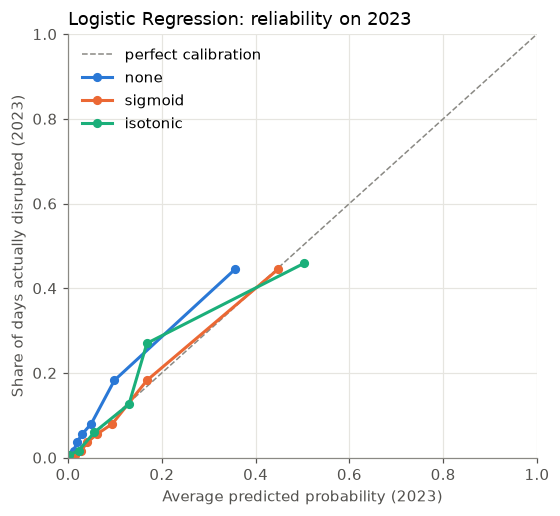

In [36]:
# 10.3 reliability plot on 2023
# Sets one plot style and colour set for the rest of the notebook, then plots the
# actual disruption share against the average prediction in 10 groups of days.
import matplotlib.pyplot as plt

# One consistent, quiet style for every plot in this notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})
MODEL_COLOR = "#2a78d6"      # blue: the model
SECOND_COLOR = "#eb6834"     # orange: second line (benchmark or alternative)
THIRD_COLOR = "#1baf7a"      # green: third line
REFERENCE_COLOR = "#8a8984"  # grey: reference lines

from sklearn.calibration import calibration_curve

option_colors = {"none": MODEL_COLOR, "sigmoid": SECOND_COLOR, "isotonic": THIRD_COLOR}

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color=REFERENCE_COLOR, linewidth=1, label="perfect calibration")
for option_name, probability in calibrate_probabilities.items():
    # strategy="quantile" makes groups with equal numbers of days; returns the actual
    # share and the mean predicted probability per group
    actual_share, mean_predicted = calibration_curve(y_calibrate, probability, n_bins=10, strategy="quantile")
    ax.plot(mean_predicted, actual_share, marker="o", markersize=5, linewidth=2,
            color=option_colors[option_name], label=option_name)
ax.set_xlabel("Average predicted probability (2023)")
ax.set_ylabel("Share of days actually disrupted (2023)")
ax.set_title(f"Logistic Regression: reliability on 2023", loc="left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False)
plt.show()

Without calibration the curve lies above the diagonal: days predicted at about 36% were disrupted about 45% of the time. The sigmoid curve is close to the diagonal. With about 438 days per point the shape is only approximate.

The alert threshold is the one with the highest F1 on 2023, searched from 0.01 to 0.90 in steps of 0.01. F1 weights missed disruptions and false alarms roughly equally; this is a convenience choice, not based on real operational costs. Because 2023 is used for both the calibration choice and the threshold choice, 2023 scores in this section are selection scores, not independent estimates.

In [37]:
# 10.4 what different thresholds would mean on 2023
# A few example thresholds show the trade-off between catching more disruptions
# (recall) and raising fewer false alarms (precision).
from sklearn.metrics import f1_score, precision_score, recall_score


def threshold_scores(y_true, probability, threshold):
    """Turn probabilities into alerts at one threshold and score the alerts.

    Args:
        y_true: actual 0/1 labels.
        probability: predicted probabilities (or benchmark rates).
        threshold: an alert is raised when probability >= threshold.

    Returns:
        dict with the threshold, number of alerts, precision, recall and F1.
    """
    alerts = (probability >= threshold).astype(int)
    return {
        "threshold": threshold,
        "alerts": int(alerts.sum()),
        # zero_division=0 returns 0 instead of a warning when there are no alerts
        "precision": precision_score(y_true, alerts, zero_division=0),
        "recall": recall_score(y_true, alerts, zero_division=0),
        "f1": f1_score(y_true, alerts, zero_division=0),
    }


calibrate_probability = calibrate_probabilities[chosen_calibration]
print("Disrupted days in 2023:", int(y_calibrate.sum()))

example_rows = []
for threshold in [0.05, 0.10, 0.20, 0.30, 0.50]:
    example_rows.append(threshold_scores(y_calibrate, calibrate_probability, threshold))
pd.DataFrame(example_rows).round(3)

Disrupted days in 2023: 364


,threshold,alerts,precision,recall,f1
0,0.05,1736,0.192,0.918,0.318
1,0.10,1029,0.279,0.788,0.412
2,0.20,540,0.419,0.621,0.500
3,0.30,326,0.488,0.437,0.461
4,0.50,134,0.590,0.217,0.317


On 2023 (364 disrupted days), a threshold of 0.05 gives 1,736 alerts with 92% recall and 19% precision; 0.50 gives 134 alerts with 59% precision and 22% recall.

In [38]:
# 10.5 choose the threshold with the highest F1 on 2023 (for the model and for the 28-day benchmark)
# Each rule is compared at its own best threshold, so the benchmark is not put at
# a disadvantage.
# np.round removes floating-point noise from arange (0.07 instead of 0.07000000000000001)
threshold_grid = np.round(np.arange(0.01, 0.91, 0.01), 2)
calibrate_rolling = rolling_rate_benchmark(calibrate_days)

model_grid_rows = []
benchmark_grid_rows = []
for threshold in threshold_grid:
    model_grid_rows.append(threshold_scores(y_calibrate, calibrate_probability, threshold))
    benchmark_grid_rows.append(threshold_scores(y_calibrate, calibrate_rolling, threshold))

model_grid = pd.DataFrame(model_grid_rows)
benchmark_grid = pd.DataFrame(benchmark_grid_rows)

alert_threshold = float(model_grid.loc[model_grid["f1"].idxmax(), "threshold"])
benchmark_threshold = float(benchmark_grid.loc[benchmark_grid["f1"].idxmax(), "threshold"])

print("Model alert threshold:            ", alert_threshold)
print("28-day benchmark alert threshold: ", benchmark_threshold)
print()
print("2023 selection scores at those thresholds (not independent estimates):")
# ** unpacks the score dict into the same row as the rule name
pd.DataFrame([
    {"rule": "Logistic Regression", **threshold_scores(y_calibrate, calibrate_probability, alert_threshold)},
    {"rule": "previous 28-day rate", **threshold_scores(y_calibrate, calibrate_rolling, benchmark_threshold)},
]).round(3)

Model alert threshold:             0.2
28-day benchmark alert threshold:  0.15

2023 selection scores at those thresholds (not independent estimates):


,rule,threshold,alerts,precision,recall,f1
0,Logistic Regression,0.20,540,0.419,0.621,0.500
1,previous 28-day rate,0.15,853,0.293,0.687,0.411


The best 2023 F1 is at threshold 0.20: 540 alerts, precision 0.42, recall 0.62, F1 0.50. The 28-day benchmark's best threshold is 0.15 with F1 0.41.

## 11. Test evaluation 2024–2025

Predictors, `C`, calibration and threshold were all fixed before this section. The test period is scored once and the results are reported as they are.

In [39]:
# 11.1 the test period
# First look at 2024-2025: size and disruption rate, overall and per year.
print("Test rows (airport-days):", len(y_test))
print(f"Disrupted days: {int(y_test.sum())} ({y_test.mean():.1%})")
print()
# NumPy array of years, used as a boolean mask on the test arrays below
test_years = test_days["year"].to_numpy()
for year in [2024, 2025]:
    in_year = test_years == year
    print(f"{year}: {in_year.sum()} rows, {int(y_test[in_year].sum())} disrupted ({y_test[in_year].mean():.1%})")

Test rows (airport-days): 8771
Disrupted days: 533 (6.1%)

2024: 4391 rows, 278 disrupted (6.3%)
2025: 4380 rows, 255 disrupted (5.8%)


8,771 airport-days, of which 533 (6.1%) were disrupted: 6.3% in 2024 and 5.8% in 2025, lower than in 2022 (6.9%) and 2023 (8.3%).

In [40]:
# 11.2 probability scores on 2024-2025 for the model and the benchmarks
# The "before calibration" row is for reference only: it shows the frozen model's own ranking, without the calibration step
# The chosen model and both benchmarks are scored once on the test years; no choice
# is changed after seeing these results.
test_probability = chosen_model.predict_proba(X_test)[:, 1]
test_constant = np.full(len(y_test), training_disruption_rate)
test_rolling = rolling_rate_benchmark(test_days)

test_rows = []
for rule_name, probability in [
    ("Logistic Regression", test_probability),
    ("Logistic Regression before calibration (reference only)", final_model.predict_proba(X_test)[:, 1]),
    ("previous 28-day rate", test_rolling),
    ("constant training rate", test_constant),
]:
    row = {"rule": rule_name}
    row.update(probability_scores(y_test, probability))
    test_rows.append(row)

test_probability_metrics = pd.DataFrame(test_rows)
test_probability_metrics.round(4)

,rule,average_precision,roc_auc,brier_score
0,Logistic Regression,0.3759,0.8885,0.0460
1,Logistic Regression before calibration (refere...,0.3759,0.8885,0.0464
2,previous 28-day rate,0.2422,0.8484,0.0501
3,constant training rate,0.0608,0.5000,0.0571


- Logistic regression: AP 0.376, ROC-AUC 0.889, Brier 0.0460.
- 28-day benchmark: AP 0.242, ROC-AUC 0.848, Brier 0.0501.
- Without calibration the AP is the same and the Brier score slightly worse (0.0464), so the sigmoid calibration chosen on 2023 still helps a little.

AP is lower than on 2022–2023 (0.45–0.47). The benchmark also dropped (0.33–0.35 to 0.24), so 2024–2025 is harder for history-based prediction in general. Part of the drop is mechanical, since AP tends to fall with a lower base rate (6.1% vs 8.3% in 2023).

In [41]:
# 11.3 alert-based scores on 2024-2025, using the thresholds chosen on 2023
# The thresholds were fixed before the test years were used, so these scores
# estimate performance on new data.
model_threshold_scores = threshold_scores(y_test, test_probability, alert_threshold)
benchmark_threshold_scores = threshold_scores(y_test, test_rolling, benchmark_threshold)

test_threshold_metrics = pd.DataFrame([
    {"rule": "Logistic Regression", **model_threshold_scores},
    {"rule": "previous 28-day rate", **benchmark_threshold_scores},
])
test_threshold_metrics.round(3)

,rule,threshold,alerts,precision,recall,f1
0,Logistic Regression,0.20,875,0.344,0.565,0.428
1,previous 28-day rate,0.15,1297,0.253,0.615,0.358


At threshold 0.20 the model raised 875 alerts with precision 0.34, recall 0.56 and F1 0.43, against F1 0.36 for the benchmark. Precision is lower than on 2023 (0.42), possibly partly because the threshold was chosen in a more disrupted year.

In [42]:
# 11.4 confusion matrix for the model on 2024-2025
# confusion_matrix returns rows = actual class (0, 1) and columns = predicted
# class (0, 1); the labels below follow that order.
from sklearn.metrics import confusion_matrix

test_alerts = (test_probability >= alert_threshold).astype(int)
matrix = confusion_matrix(y_test, test_alerts)
pd.DataFrame(
    matrix,
    index=["actual: normal day", "actual: disrupted day"],
    columns=["predicted: no alert", "predicted: alert"],
)

,predicted: no alert,predicted: alert
actual: normal day,7664,574
actual: disrupted day,232,301


301 disrupted days were caught, 232 were missed and 574 normal days received an alert. About two of three alerts were false alarms and about four of ten disrupted days had no alert. Whether this is acceptable depends on the relative costs of the two errors, which are not known here.

Precision-recall curves on 2024–2025. The dot marks the threshold chosen on 2023; the dashed line is the base rate.

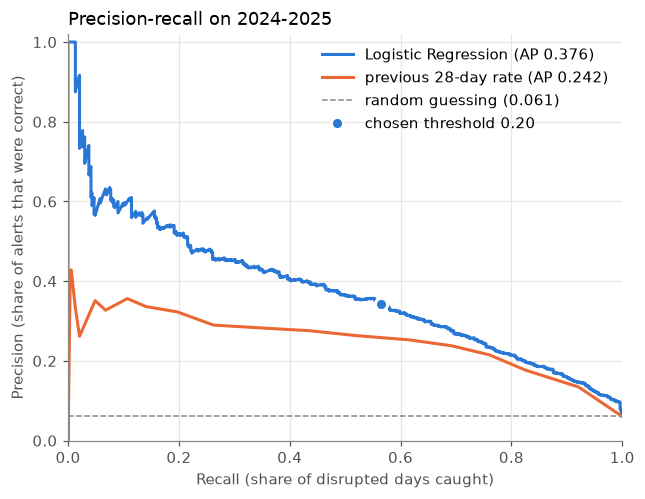

In [43]:
# 11.5 precision-recall curves on 2024-2025
# Precision and recall at every possible threshold. The dashed line is the precision
# of random alerts, which equals the disruption rate.
from sklearn.metrics import precision_recall_curve

# Returns precision, recall and the thresholds (not needed here)
model_precision, model_recall, _ = precision_recall_curve(y_test, test_probability)
rolling_precision, rolling_recall, _ = precision_recall_curve(y_test, test_rolling)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.plot(model_recall, model_precision, color=MODEL_COLOR, linewidth=2,
        label=f"Logistic Regression (AP {average_precision_score(y_test, test_probability):.3f})")
ax.plot(rolling_recall, rolling_precision, color=SECOND_COLOR, linewidth=2,
        label=f"previous 28-day rate (AP {average_precision_score(y_test, test_rolling):.3f})")
ax.axhline(y_test.mean(), color=REFERENCE_COLOR, linestyle="--", linewidth=1,
           label=f"random guessing ({y_test.mean():.3f})")
# Marks where the threshold chosen on 2023 lands on the test curve
ax.plot(model_threshold_scores["recall"], model_threshold_scores["precision"], marker="o", markersize=8,
        color=MODEL_COLOR, markeredgecolor="white", markeredgewidth=2, linestyle="none",
        label=f"chosen threshold {alert_threshold:.2f}")
ax.set_xlabel("Recall (share of disrupted days caught)")
ax.set_ylabel("Precision (share of alerts that were correct)")
ax.set_title("Precision-recall on 2024-2025", loc="left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="upper right")
plt.show()

The model's curve lies above the benchmark at almost every recall level. About three quarters of the 20 highest-risk days were disrupted, and precision falls steadily as the threshold decreases. The chosen threshold corresponds to about 56% recall and 34% precision.

In [44]:
# 11.6 does performance hold in both test years?
# Same metrics per year, to check that the result is not driven by one year only.
year_rows = []
for year in [2024, 2025]:
    in_year = test_years == year
    year_rows.append({
        "year": year,
        "rows": int(in_year.sum()),
        "disrupted_days": int(y_test[in_year].sum()),
        "model_AP": average_precision_score(y_test[in_year], test_probability[in_year]),
        "benchmark_28d_AP": average_precision_score(y_test[in_year], test_rolling[in_year]),
        "model_recall": recall_score(y_test[in_year], test_alerts[in_year], zero_division=0),
        "model_precision": precision_score(y_test[in_year], test_alerts[in_year], zero_division=0),
    })
pd.DataFrame(year_rows).round(3)

,year,rows,disrupted_days,model_AP,benchmark_28d_AP,model_recall,model_precision
0,2024,4391,278,0.365,0.245,0.522,0.326
1,2025,4380,255,0.389,0.239,0.612,0.363


AP was 0.365 in 2024 and 0.389 in 2025, against about 0.24 for the benchmark in both years, so the result is not driven by a single year.

## 12. Results by airport

Airports with fewer than 20 disrupted test days are flagged, since their metrics are unstable. AP and recall are undefined without disrupted days and precision is undefined without alerts; these cells are left as `NaN`. Consecutive days are correlated, so the effective sample size is smaller than the row count.

In [45]:
# 12.1 one row per airport for 2024-2025
# AP and recall need at least one disrupted and one normal day, precision needs at
# least one alert; otherwise the value is left as NaN.
test_results = test_days[["airport_icao", "airport_name", "date", "year"]].copy()
test_results["actual"] = y_test.to_numpy()
test_results["probability"] = test_probability
test_results["alert"] = test_alerts
test_results["benchmark_28d"] = test_rolling

airport_rows = []
for airport, group in test_results.groupby("airport_icao"):
    disrupted_days = int(group["actual"].sum())
    alerts = int(group["alert"].sum())
    row = {
        "airport": airport,
        "name": group["airport_name"].iloc[0],
        "days": len(group),
        "disrupted_days": disrupted_days,
        "alerts": alerts,
        # Flag airports with fewer than 20 disrupted days, where scores are unstable
        "few_events": disrupted_days < 20,
        "model_AP": np.nan,
        "benchmark_28d_AP": np.nan,
        "recall": np.nan,
        "precision": np.nan,
    }
    if 0 < disrupted_days < len(group):
        row["model_AP"] = average_precision_score(group["actual"], group["probability"])
        row["benchmark_28d_AP"] = average_precision_score(group["actual"], group["benchmark_28d"])
        row["recall"] = recall_score(group["actual"], group["alert"])
    if alerts > 0:
        row["precision"] = precision_score(group["actual"], group["alert"])
    row["brier_score"] = brier_score_loss(group["actual"], group["probability"])
    airport_rows.append(row)

airport_metrics = pd.DataFrame(airport_rows).sort_values("disrupted_days", ascending=False)
airport_metrics.round(3)

,airport,name,days,disrupted_days,alerts,few_events,model_AP,benchmark_28d_AP,recall,precision,brier_score
1,EDDF,Frankfurt,731,198,397,False,0.548,0.304,0.793,0.395,0.166
4,EDDK,Cologne-Bonn,731,124,199,False,0.433,0.294,0.637,0.397,0.117
6,EDDM,Munich,731,85,161,False,0.330,0.202,0.553,0.292,0.090
9,EDDS,Stuttgart,731,52,10,False,0.174,0.109,0.058,0.300,0.064
8,EDDP,Leipzig-Halle,731,38,24,False,0.156,0.057,0.132,0.208,0.050
5,EDDL,Duesseldorf,731,25,31,False,0.165,0.035,0.320,0.258,0.033
3,EDDH,Hamburg,731,8,42,True,0.037,0.022,0.250,0.048,0.021
2,EDDG,Muenster-Osnabrueck,731,1,0,True,0.004,0.001,0.000,NaN,0.001
7,EDDN,Nuremberg,731,1,0,True,0.005,0.001,0.000,NaN,0.001
11,EDDW,Bremen,731,1,9,True,0.002,0.001,0.000,0.000,0.007


- Frankfurt (198 disrupted days) has AP 0.548 and recall 0.79, Cologne-Bonn (124) AP 0.433 and Munich (85) AP 0.330. These three airports account for most events and most of the performance.
- Stuttgart had 52 disrupted days but only 10 alerts, of which 3 were correct (recall 0.06), the clearest failure.
- Disruption patterns shifted between training and test: Düsseldorf fell from 15.6% to 3.4% of days (25 days), Hamburg from 9.1% to 1.1% (8 days), while Cologne-Bonn rose from 7.2% to 17%.
- Münster-Osnabrück, Nuremberg and Bremen had one disrupted day each, so their AP values are not meaningful; Dresden and Hannover had none. Hannover still received 2 false alerts and Bremen 9.
- Frankfurt has the highest Brier score (0.166), reflecting the most uncertain outcomes.

## 13. Interpretation

Coefficients (cell 13.1) refer to standardized inputs, so `exp(coefficient)` is the odds multiplier for a one-standard-deviation increase with the other inputs held fixed. Permutation importance (cell 13.2) is the drop in 2023 AP when a column is shuffled; it is descriptive only and not used for any decision. Correlated inputs share influence, and neither measure implies causation.

In [46]:
# 13.1 coefficients of the frozen model (standardized inputs)
# With standardized inputs a coefficient is the change in log-odds for one standard
# deviation; exp(coefficient) is the matching odds multiplier.
# Uncalibrated model: the sigmoid calibration rescales scores but keeps their order
classifier = final_model.named_steps["classifier"]
feature_names = final_model.named_steps["preprocess"].get_feature_names_out()

coefficients = pd.DataFrame({"feature": feature_names, "coefficient": classifier.coef_[0]})
# Remove the ColumnTransformer prefixes from the feature names
coefficients["feature"] = coefficients["feature"].str.replace("numeric__", "").str.replace("airport__", "")
coefficients["odds_multiplier"] = np.exp(coefficients["coefficient"])
coefficients = coefficients.sort_values("coefficient", ascending=False)

print("Ten largest positive coefficients (push risk up):")
display(coefficients.head(10).round(3))
print("Ten largest negative coefficients (push risk down):")
display(coefficients.tail(10).round(3))

Ten largest positive coefficients (push risk up):


,feature,coefficient,odds_multiplier
40,airport_icao_EDDK,1.132,3.102
47,airport_icao_EDDW,1.118,3.060
44,airport_icao_EDDP,1.104,3.015
39,airport_icao_EDDH,0.952,2.590
27,arrivals_lag7,0.858,2.358
41,airport_icao_EDDL,0.787,2.198
8,temp_max_c,0.687,1.988
45,airport_icao_EDDS,0.640,1.896
34,disrupted_rate_28d,0.447,1.564
26,arrivals_lag1,0.356,1.427


Ten largest negative coefficients (push risk down):


,feature,coefficient,odds_multiplier
35,weather_delay_per_arrival_mean_28d,-0.193,0.824
4,is_weekend,-0.203,0.816
3,doy_cos,-0.257,0.773
6,temp_mean_c,-0.635,0.530
46,airport_icao_EDDV,-1.062,0.346
42,airport_icao_EDDM,-1.335,0.263
37,airport_icao_EDDF,-1.399,0.247
43,airport_icao_EDDN,-1.444,0.236
36,airport_icao_EDDC,-1.820,0.162
38,airport_icao_EDDG,-2.047,0.129


- The airport indicators have the largest coefficients. Frankfurt, the most disrupted airport, has a negative coefficient (odds × 0.25), while `arrivals_lag7` is strongly positive (+0.86). The model explains much of Frankfurt's risk through traffic volume and uses the airport indicator as a correction, so these coefficients cannot be interpreted separately.
- `temp_max_c` is positive (+0.69) and `temp_mean_c` negative (−0.64). Together they roughly mean that warm afternoons relative to the daily mean raise risk; whether this reflects summer thunderstorm days cannot be determined from this model.
- Weekends lower the odds (× 0.82) and a high recent disruption rate raises them (× 1.56 per standard deviation).

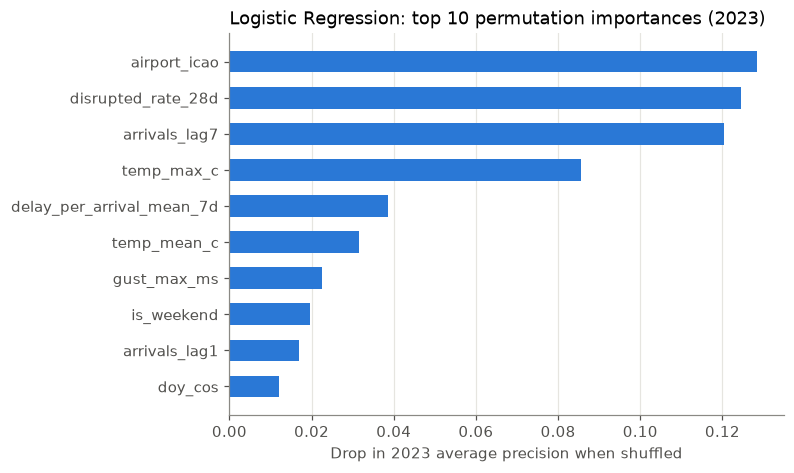

,feature,AP_drop_mean,AP_drop_std
0,airport_icao,0.1285,0.0176
35,disrupted_rate_28d,0.1246,0.0068
28,arrivals_lag7,0.1204,0.0067
9,temp_max_c,0.0857,0.0072
33,delay_per_arrival_mean_7d,0.0387,0.0065
7,temp_mean_c,0.0316,0.0077
14,gust_max_ms,0.0224,0.0030
5,is_weekend,0.0197,0.0024
27,arrivals_lag1,0.0170,0.0043
4,doy_cos,0.0120,0.0033


In [47]:
# 13.2 permutation importance on 2023 (drop in average precision when a column is shuffled)
# Each input column is shuffled 5 times with a fixed seed; airport_icao is shuffled
# as one column, before the one-hot encoding inside the pipeline.
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    final_model, X_calibrate, y_calibrate,
    scoring="average_precision", n_repeats=5, random_state=RANDOM_SEED,
)
permutation_table = pd.DataFrame({
    "feature": X_calibrate.columns,
    "AP_drop_mean": permutation.importances_mean,
    "AP_drop_std": permutation.importances_std,
}).sort_values("AP_drop_mean", ascending=False)

# iloc[::-1] reverses the order so the largest bar is drawn at the top
top_permutation = permutation_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(top_permutation["feature"], top_permutation["AP_drop_mean"], color=MODEL_COLOR, height=0.6)
ax.set_xlabel("Drop in 2023 average precision when shuffled")
ax.set_title("Logistic Regression: top 10 permutation importances (2023)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
plt.show()

permutation_table.head(10).round(4)

The largest AP drops on 2023 come from airport (−0.129), the 28-day disruption rate (−0.125), arrivals a week earlier (−0.120) and maximum temperature (−0.086). Other weather plays a small role: maximum gust −0.022, and thunderstorm hours are not in the top 10. Shuffling the airport breaks the airport-traffic combination described above.

In [48]:
# 13.3 how strongly do the history predictors overlap? (training years)
# High correlations mean these columns carry similar information, which makes their
# individual coefficients hard to interpret.
history_columns = [
    "delay_per_arrival_lag1", "share_delayed15_lag1", "disrupted_lag1",
    "delay_per_arrival_mean_7d", "delay_per_arrival_mean_28d", "disrupted_rate_28d",
]
X_train[history_columns].corr().round(2)

,delay_per_arrival_lag1,share_delayed15_lag1,disrupted_lag1,delay_per_arrival_mean_7d,delay_per_arrival_mean_28d,disrupted_rate_28d
delay_per_arrival_lag1,1.00,0.94,0.68,0.52,0.37,0.33
share_delayed15_lag1,0.94,1.00,0.76,0.52,0.38,0.35
disrupted_lag1,0.68,0.76,1.00,0.44,0.37,0.43
delay_per_arrival_mean_7d,0.52,0.52,0.44,1.00,0.72,0.63
delay_per_arrival_mean_28d,0.37,0.38,0.37,0.72,1.00,0.87
disrupted_rate_28d,0.33,0.35,0.43,0.63,0.87,1.00


Several history columns are strongly correlated: 0.94 between yesterday's delay per arrival and yesterday's share delayed by more than 15 minutes, and 0.87 between the 28-day mean delay and the 28-day disruption rate. Individual coefficients and importances of these columns should not be over-interpreted.

## 14. Saved outputs

Saved to `outputs/03_logistic_regression/`: `model.joblib` (frozen pipeline including fitted preprocessing, calibration wrapper, threshold, predictor list, settings and library versions), `test_predictions_2024_2025.csv`, `test_metrics.csv`, `airport_metrics.csv`, `tuning_results.csv` and `calibration_results.csv`. The model is then reloaded to check that it reproduces the saved predictions.

In [49]:
# 14.1 save everything needed to reuse and check this model
# One joblib file with the calibrated model, the uncalibrated model, the threshold
# and the settings, plus the test predictions and metric tables as CSV.
import joblib

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "03_logistic_regression"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

saved_model = {
    "model": chosen_model,
    "uncalibrated_model": final_model,
    "calibration": chosen_calibration,
    "alert_threshold": alert_threshold,
    "predictor_columns": predictor_columns,
    "settings": {"C": best_c, "random_seed": RANDOM_SEED},
    "training_years": "2014-2021",
    "description": "logistic regression pipeline (median fill + standardize + one-hot airport) with the chosen C",
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__},
}
joblib.dump(saved_model, OUTPUT_DIR / "model.joblib")

# how="left" keeps the rules that have no alert threshold (constant benchmark and
# the uncalibrated reference); their alert columns stay empty
test_metrics = test_probability_metrics.merge(test_threshold_metrics, on="rule", how="left")
test_metrics.loc[test_metrics["rule"] == "Logistic Regression", "select_2022_AP"] = average_precision_score(y_select, final_select_probability)
test_metrics.loc[test_metrics["rule"] == "Logistic Regression", "calibration"] = chosen_calibration

test_results.to_csv(OUTPUT_DIR / "test_predictions_2024_2025.csv", index=False)
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
airport_metrics.to_csv(OUTPUT_DIR / "airport_metrics.csv", index=False)
tuning_results.to_csv(OUTPUT_DIR / "tuning_results.csv", index=False)
calibration_results.to_csv(OUTPUT_DIR / "calibration_results.csv", index=False)

for saved_file in sorted(OUTPUT_DIR.iterdir()):
    print(saved_file.name)

airport_metrics.csv
calibration_results.csv
model.joblib
test_metrics.csv
test_predictions_2024_2025.csv
tuning_results.csv


In [50]:
# 14.2 reload the saved model and check it reproduces the saved predictions
# np.allclose allows for tiny floating-point differences.
reloaded = joblib.load(OUTPUT_DIR / "model.joblib")
reloaded_probability = reloaded["model"].predict_proba(X_test)[:, 1]
print("Reloaded model gives identical test probabilities:", np.allclose(reloaded_probability, test_probability))
print("Saved alert threshold:", reloaded["alert_threshold"])

Reloaded model gives identical test probabilities: True
Saved alert threshold: 0.2


The reloaded model reproduces the test probabilities exactly. Inputs must be prepared as in cell 5.3; the stored threshold is 0.20.

## Summary

- Test AP 0.376 against 0.242 for the 28-day benchmark; ROC-AUC 0.889, Brier 0.0460 after sigmoid calibration (0.0464 without).
- At threshold 0.20: 875 alerts, precision 0.34, recall 0.56, F1 0.43 (benchmark F1 0.36); about two false alarms per correct alert.
- AP 0.365 in 2024 and 0.389 in 2025, so the result is consistent across both test years.
- Performance is uneven by airport: good at Frankfurt and Cologne-Bonn, poor at Stuttgart, and not assessable at the five quietest airports.
- All results assume perfect knowledge of same-day weather.

Notebook 04 fits LightGBM on the same rows.